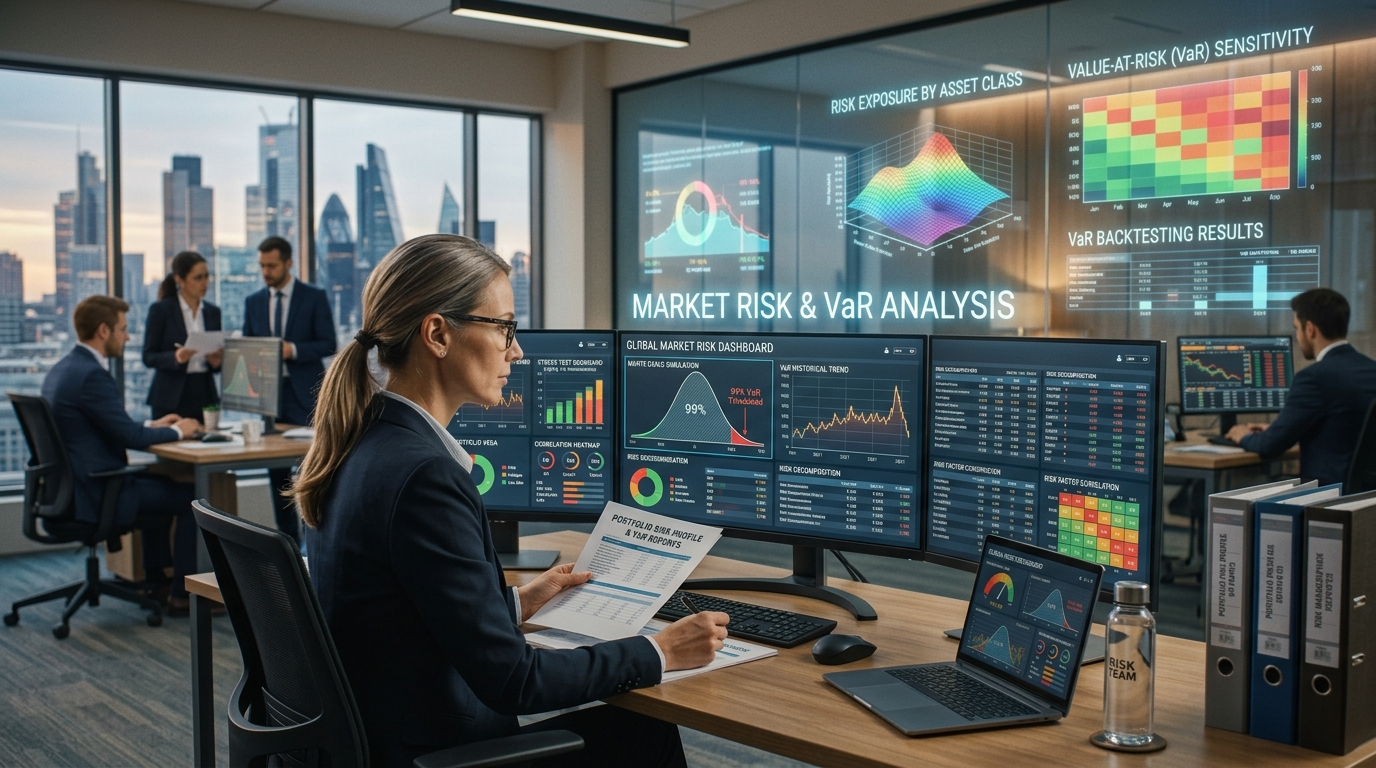

# Market Risk: Value at Risk (VaR)

## Business Importance

Market risk analytics is central to how financial institutions protect capital and make trading and investment decisions, with direct implications for profitability, regulatory compliance, and institutional stability.

Value at Risk (VaR) and Expected Shortfall (ES) let risk teams quantify potential portfolio losses, set position and trading limits, allocate capital, and report exposure to management and regulators. The reliability of these estimates matters as much as the estimates themselves: a model that works in calm markets but fails in stress periods gives false confidence at the worst possible time.

## Business Problem

Institutions holding multi-asset portfolios need a daily, defensible estimate of how much they could lose, but any single VaR methodology carries blind spots. Historical Simulation reflects only what occurred in the sample, parametric VaR assumes normally distributed returns, and Monte Carlo inherits the assumptions of its inputs.

Relying on one method, or on a model that is never tested against realized losses, can lead to underestimated risk, poorly sized capital buffers, and limits that fail when they are needed most.


## Project Objective

The goal of this project is to build a transparent, multi-method framework to measure and validate market risk for a diversified portfolio. It estimates 1-day and 10-day VaR at 95% and 99% confidence with three methodologies, adds Expected Shortfall to capture tail severity, and tests the results through backtesting (Kupiec test) and crisis-period stress testing.

The outcome is a clearer view of where the methods agree, where they diverge, and how much the estimates can be trusted. That view supports more conservative risk reporting, informed limit-setting, and a monitoring approach that triggers model review when exception rates or volatility regimes change.

## Gettting ready for the analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.stats import norm
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:.6f}".format)

df = pd.read_csv("market_risk_var.csv", parse_dates=["Date"])
df['Date'] = pd.to_datetime(df['Date'])
df

,Date,Asset_ID,Asset_Class,Sector,Currency,Price,Return,Volatility,Position_Size
0,2020-01-01,AAPL,Equity,Technology,USD,150.000000,0.000119,NaN,388.090000
1,2020-01-02,AAPL,Equity,Technology,USD,150.217600,0.001451,0.000942,388.090000
2,2020-01-03,AAPL,Equity,Technology,USD,150.095600,-0.000812,0.001138,388.090000
3,2020-01-06,AAPL,Equity,Technology,USD,150.183300,0.000584,0.000943,388.090000
4,2020-01-07,AAPL,Equity,Technology,USD,150.279000,0.000637,0.000828,388.090000
...,...,...,...,...,...,...,...,...,...
12511,2023-12-25,BTC-X,Commodity,Crypto,USD,24822.195700,0.003095,0.003517,3.310000
12512,2023-12-26,BTC-X,Commodity,Crypto,USD,24731.487100,-0.003654,0.003561,3.310000
12513,2023-12-27,BTC-X,Commodity,Crypto,USD,24785.719800,0.002193,0.003490,3.310000
12514,2023-12-28,BTC-X,Commodity,Crypto,USD,24856.838500,0.002869,0.003538,3.310000


### Data Explanation

The dataset is a daily panel of 12 instruments across equities, commodities (including a crypto proxy), FX and fixed income, covering 1,043 business days from 2020-01-01 to 2023-12-29 (12,516 rows).

| Variable | Description |
| :--- | :--- |
| `Date` | Business-day timestamp; defines the horizon for returns and rolling windows |
| `Asset_ID` | Instrument identifier (e.g. AAPL, EUR=X, GLD) |
| `Asset_Class` | Equity, FX, Commodity or Fixed Income; used to aggregate risk by class |
| `Sector` | Industry or sub-class (Technology, Energy, Gold, Bonds, ...); used for sector-level VaR |
| `Currency` | Base currency of the instrument |
| `Price` | Daily closing price in local currency |
| `Return` | Daily simple return, `price_t / price_t-1 - 1`; input to all three VaR models |
| `Volatility` | 20-day rolling standard deviation of returns |
| `Position_Size` | Units held; scales each asset's return to dollar P&L |

### Data Stats

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12516 entries, 0 to 12515
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           12516 non-null  datetime64[ns]
 1   Asset_ID       12516 non-null  object        
 2   Asset_Class    12516 non-null  object        
 3   Sector         12516 non-null  object        
 4   Currency       12516 non-null  object        
 5   Price          12516 non-null  float64       
 6   Return         12516 non-null  float64       
 7   Volatility     12504 non-null  float64       
 8   Position_Size  12516 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(4)
memory usage: 880.2+ KB


In [4]:
df.describe()

,Date,Price,Return,Volatility,Position_Size
count,12516,12516.000000,12516.000000,12504.000000,12516.000000
mean,2021-12-30 09:34:20.594439168,2637.492328,-0.000025,0.001578,12340.866667
min,2020-01-01 00:00:00,1.089300,-0.015090,0.000095,3.310000
25%,2020-12-30 00:00:00,71.223575,-0.000819,0.000652,348.485000
50%,2021-12-30 00:00:00,133.799950,0.000000,0.001537,906.095000
75%,2022-12-30 00:00:00,196.687875,0.000784,0.002134,1586.435000
max,2023-12-29 00:00:00,31518.111000,0.011892,0.006167,81059.100000
std,NaN,7495.564830,0.001878,0.001009,26283.168379


In [5]:
df.isnull().sum()

Date              0
Asset_ID          0
Asset_Class       0
Sector            0
Currency          0
Price             0
Return            0
Volatility       12
Position_Size     0
dtype: int64

## Data Analysis

### Average Daily Return by Asset Class

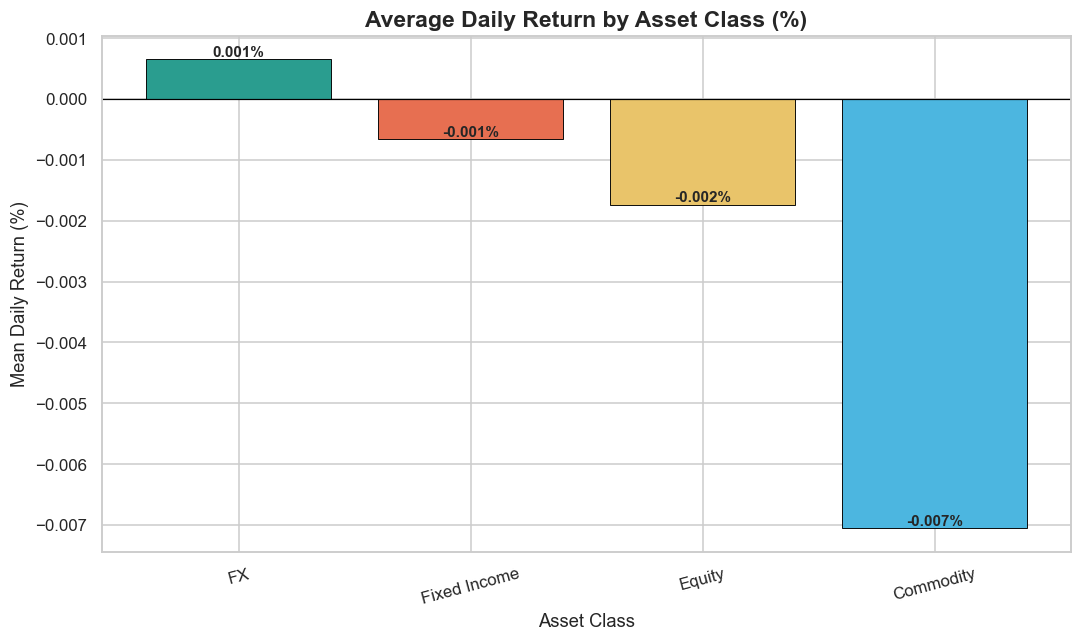

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

avg_ret = (
    df.groupby("Asset_Class")["Return"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 6))
bars = plt.bar(
    avg_ret["Asset_Class"],
    avg_ret["Return"] * 100,
    color=["#2A9D8F", "#E76F51", "#E9C46A", "#4cb6e0", "#F4A261", "#EDE8D0"][:len(avg_ret)],
    edgecolor="black",
    linewidth=0.6,
)
for b, v in zip(bars, avg_ret["Return"] * 100):
    plt.text(b.get_x() + b.get_width()/2, v, f"{v:.3f}%",
             ha="center", va="bottom", fontsize=10, weight="bold")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Average Daily Return by Asset Class (%)", fontsize=15, weight="bold")
plt.ylabel("Mean Daily Return (%)", fontsize=12)
plt.xlabel("Asset Class", fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Conclusion:** The chart reveals a clear disparity in average daily returns across asset classes, highlighting FX as the only category with a positive return (0.001%). In contrast, Commodity shows the most significant decline at -0.007%, positioning it as the worst-performing asset in the group. Fixed Income and Equity display moderate and similar losses (-0.001% and -0.002% respectively), indicating a generalized downward trend across most of the investments analyzed. Overall, the chart suggests a predominantly negative market environment for this period, where only a minority managed to generate gains.

### Average Daily Return by Sector

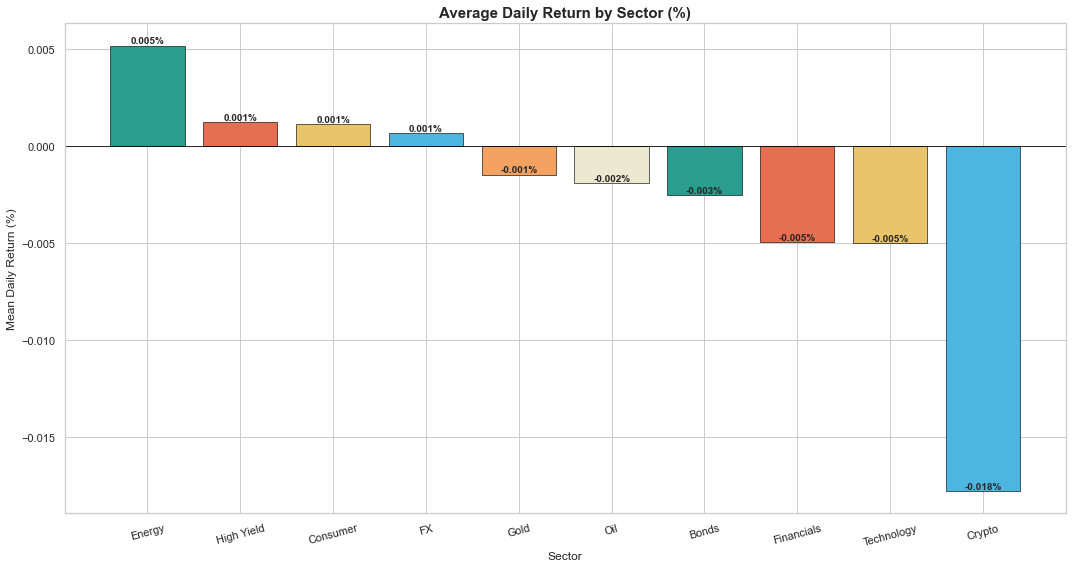

In [4]:
avg_ret = (
    df.groupby("Sector")["Return"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(15, 8))
bars = plt.bar(
    avg_ret["Sector"],
    avg_ret["Return"] * 100,
    color=["#2A9D8F", "#E76F51", "#E9C46A", "#4cb6e0", "#F4A261", "#EDE8D0"][:len(avg_ret)],
    edgecolor="black",
    linewidth=0.6,
)
for b, v in zip(bars, avg_ret["Return"] * 100):
    plt.text(b.get_x() + b.get_width()/2, v, f"{v:.3f}%",
             ha="center", va="bottom", fontsize=10, weight="bold")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Average Daily Return by Sector (%)", fontsize=15, weight="bold")
plt.ylabel("Mean Daily Return (%)", fontsize=12)
plt.xlabel("Sector", fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Conclusion:** Based on the chart, the Energy sector stands out as the clear leader with the only notable positive average daily return at 0.005%, followed by modest gains in High Yield, Consumer, and FX. Conversely, the Crypto sector exhibits a severe negative outlier at -0.018%, far exceeding the losses seen in any other category. Most other sectors, including Financials, Industrials, Bonds, and Oil, show moderate negative returns ranging between -0.001% and -0.006%. Overall, the data indicates a broadly bearish market sentiment across sectors, heavily dragged down by the drastic underperformance of cryptocurrencies.

### Rolling Volatility by Asset

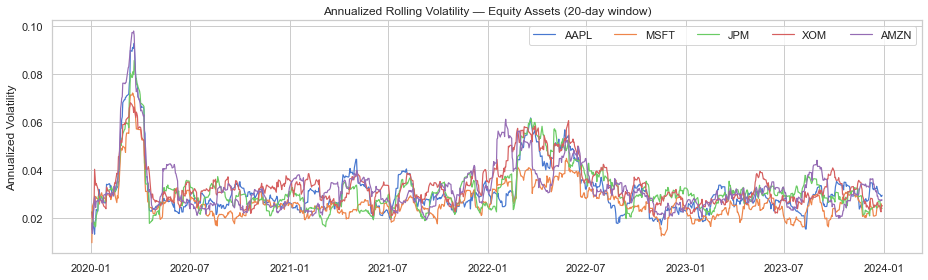

In [11]:
vol_wide = df.pivot_table(index="Date", columns="Asset_ID", values="Volatility")
equity_assets = ["AAPL", "MSFT", "JPM", "XOM", "AMZN"]

fig, ax = plt.subplots(figsize=(13, 4))
for asset in equity_assets:
    ax.plot(vol_wide.index, vol_wide[asset] * np.sqrt(252),
            label=asset, linewidth=1.2)
ax.set_title("Annualized Rolling Volatility — Equity Assets (20-day window)")
ax.set_ylabel("Annualized Volatility")
ax.legend(ncol=5)
plt.tight_layout()
plt.show()

**Conclusion:** The chart illustrates that rolling volatility for major equity assets is highly synchronized, with all five stocks exhibiting similar directional trends and peak periods. A significant spike occurred in early 2020, where volatility surged past 0.10, marking the highest risk period shown. A second, more moderate volatility cluster emerged around early to mid-2022, reaching approximately 0.06 before gradually subsiding. Following this period, volatility generally stabilized at lower levels between 0.02 and 0.04 through 2023 into early 2024, indicating a more settled market environment.

### Return Distributions by Asset Class

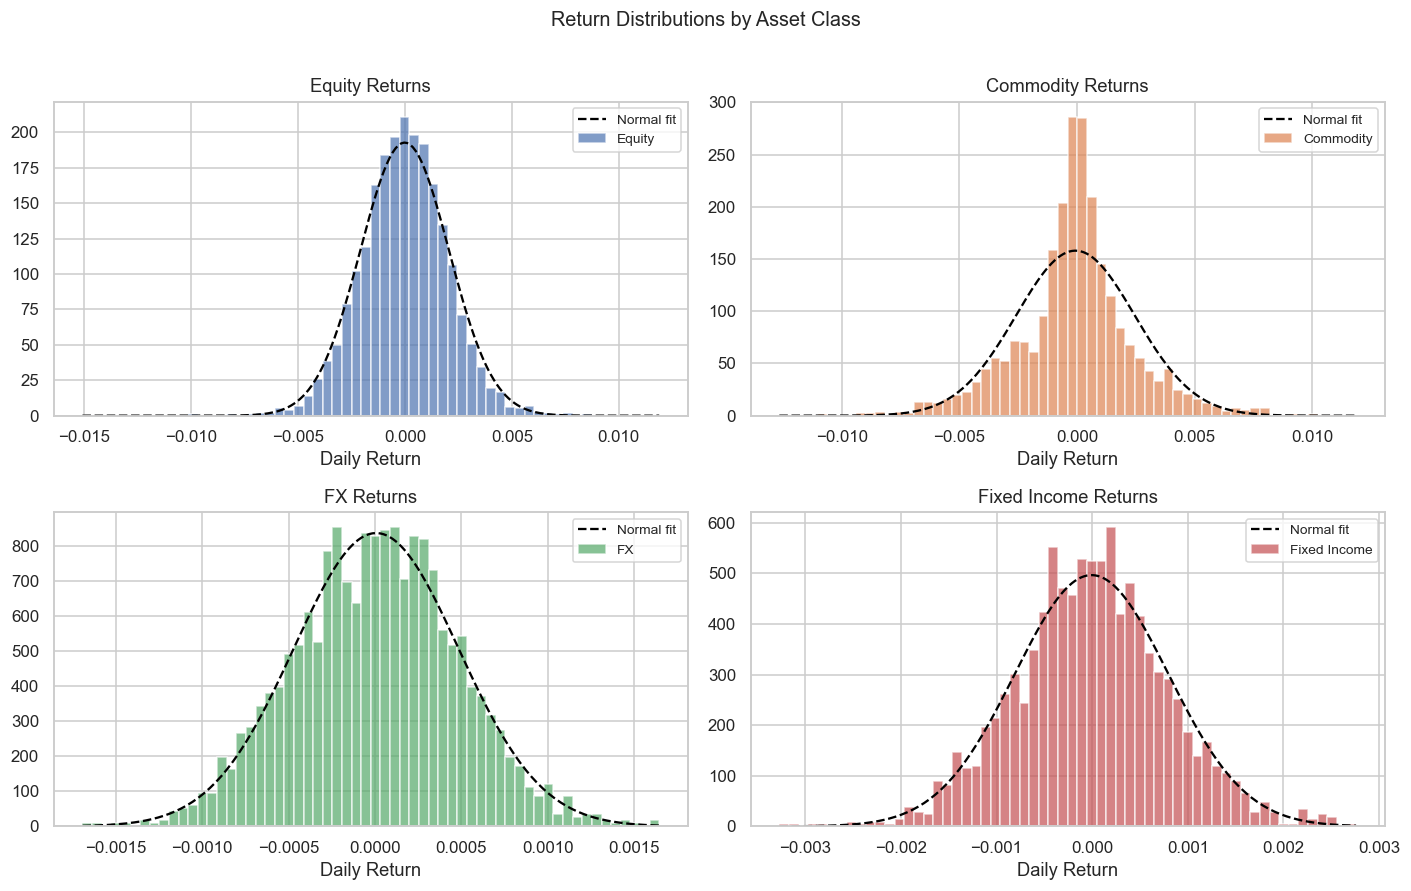

In [9]:
returns_wide = df.pivot_table(index="Date", columns="Asset_ID", values="Return")

asset_classes = df.groupby("Asset_ID")["Asset_Class"].first()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
classes = ["Equity", "Commodity", "FX", "Fixed Income"]
colors  = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

for ax, cls, col in zip(axes.flatten(), classes, colors):
    assets = asset_classes[asset_classes == cls].index.tolist()
    data = returns_wide[assets].stack().dropna()
    ax.hist(data, bins=60, color=col, alpha=0.7, density=True, label=cls)
    mu, sigma = data.mean(), data.std()
    x = np.linspace(data.min(), data.max(), 200)
    ax.plot(x, norm.pdf(x, mu, sigma), color="black", lw=1.5, linestyle="--", label="Normal fit")
    ax.set_title(f"{cls} Returns")
    ax.set_xlabel("Daily Return")
    ax.legend(fontsize=9)

plt.suptitle("Return Distributions by Asset Class", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**Conclusion:** The charts demonstrate that daily returns across all four asset classes are centered near zero, indicating a general balance between positive and negative movements. Equity and Commodity returns exhibit wider spreads and "fatter tails" compared to the normal distribution curve, suggesting higher risk and a greater likelihood of extreme daily fluctuations. In contrast, Fixed Income shows a notably narrower distribution, reflecting lower volatility and more tightly clustered returns. FX returns appear relatively symmetric and closely follow the normal fit, presenting a moderate risk profile between the highly volatile commodities and the stable fixed income assets.

### Portfolio Daily P&L Summary Statistics

In [10]:
# Pivot to wide format: one column per asset
returns_wide = df.pivot_table(index="Date", columns="Asset_ID", values="Return")
prices_wide  = df.pivot_table(index="Date", columns="Asset_ID", values="Price")

# Position sizes (constant per asset)
position_map = df.groupby("Asset_ID")["Position_Size"].first()

# Dollar P&L per asset per day
pnl_wide = returns_wide.multiply(
    prices_wide.shift(1), axis=0
).multiply(position_map, axis=1)

# Portfolio-level daily P&L
portfolio_pnl = pnl_wide.sum(axis=1).dropna()

print(f"Assets          : {returns_wide.shape[1]}")
print(f"Trading days    : {returns_wide.shape[0]}")
print(f"Portfolio P&L mean  : ${portfolio_pnl.mean():,.0f}")
print(f"Portfolio P&L std   : ${portfolio_pnl.std():,.0f}")
print(f"Worst single day    : ${portfolio_pnl.min():,.0f}")
print(f"Best single day     : ${portfolio_pnl.max():,.0f}")

Assets          : 12
Trading days    : 1043
Portfolio P&L mean  : $-30
Portfolio P&L std   : $878
Worst single day    : $-4,719
Best single day     : $4,106


**Conclusion:** Based on the code output, the portfolio generated a marginally negative mean daily P&L of -38 USD across 1,043 trading days for 12 assets. The P&L standard deviation of 878 USD indicates moderate daily volatility, with the worst single day resulting in a loss of - 4,719 USD and the best single day yielding a gain of 4,106 USD. Overall, the strategy shows a slight negative average performance with asymmetric downside risk, as the maximum loss exceeds the maximum gain.

##  VaR methods and comparison

### Historical Simulation

Takes the actual distribution of daily portfolio P&L and reads the loss threshold at the 5th and 1st percentiles. It makes no distributional assumption, but it can only reflect what happened in the sample. Expected Shortfall is the average loss on days beyond the 99% VaR; the shaded area marks that tail.

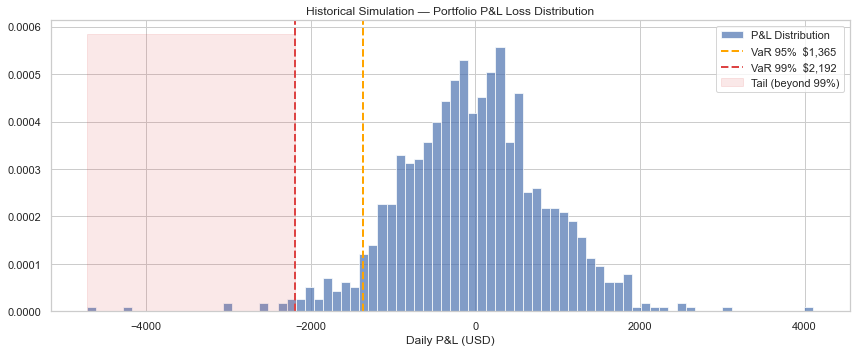

Historical VaR 95% : $       1,365
Historical VaR 99% : $       2,192
Expected Shortfall  : $       2,851  (average loss beyond VaR 99%)


In [18]:
CONFIDENCE_LEVELS = [0.95, 0.99]

def historical_var(pnl_series, confidence=0.99):
    return -np.percentile(pnl_series, (1 - confidence) * 100)

hs_var_95 = historical_var(portfolio_pnl, 0.95)
hs_var_99 = historical_var(portfolio_pnl, 0.99)
hs_es_99  = -portfolio_pnl[portfolio_pnl <= -hs_var_99].mean()  # Expected Shortfall

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(portfolio_pnl, bins=80, color="#4C72B0", alpha=0.7, density=True, label="P&L Distribution")
ax.axvline(-hs_var_95, color="#FFA500", linewidth=2, linestyle="--", label=f"VaR 95%  ${hs_var_95:,.0f}")
ax.axvline(-hs_var_99, color="#DD4444", linewidth=2, linestyle="--", label=f"VaR 99%  ${hs_var_99:,.0f}")
ax.fill_betweenx([0, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 0.0003],
                 portfolio_pnl.min(), -hs_var_99,
                 color="#DD4444", alpha=0.12, label="Tail (beyond 99%)")
ax.set_title("Historical Simulation — Portfolio P&L Loss Distribution")
ax.set_xlabel("Daily P&L (USD)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Historical VaR 95% : ${hs_var_95:>12,.0f}")
print(f"Historical VaR 99% : ${hs_var_99:>12,.0f}")
print(f"Expected Shortfall  : ${hs_es_99:>12,.0f}  (average loss beyond VaR 99%)")

**Conclusion:** The portfolio's daily P&L distribution is heavily skewed to the left, indicating that extreme losses are more frequent and severe than extreme gains. The Value at Risk (VaR) analysis shows that with 95% confidence, daily losses will not exceed 1,365 USD, while at 0.99 confidence, the maximum expected loss rises to 2,192  USD. Also, the Expected Shortfall of $2,851 reveals that on the rare occasions when losses breach the 0.99 VaR threshold, the average loss is significantly larger, highlighting substantial tail risk that investors must be prepared to absorb.

### Variance-Covariance

Assumes portfolio P&L is normally distributed and computes VaR from its mean and standard deviation. It is fast and transparent, but only as good as the normality assumption, which is checked with a Shapiro-Wilk test.

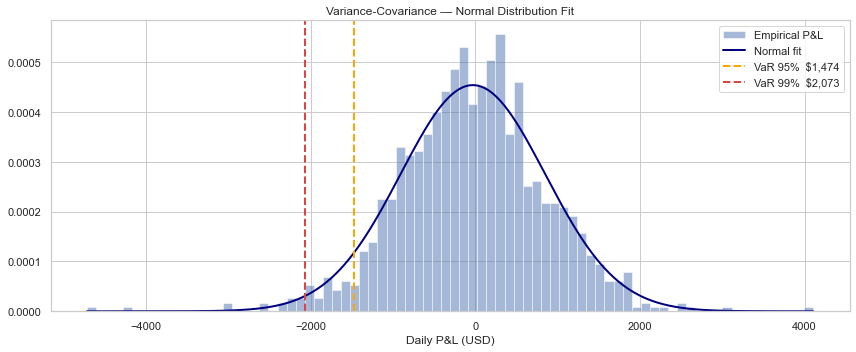

Parametric VaR 95% : $       1,474
Parametric VaR 99% : $       2,073

Shapiro-Wilk normality test on P&L sample:
  W=0.9969  p=4.5645e-01  →  Cannot reject normality


In [17]:
mu_p    = portfolio_pnl.mean()
sigma_p = portfolio_pnl.std()

vc_var_95 = -(mu_p + norm.ppf(0.05) * sigma_p)
vc_var_99 = -(mu_p + norm.ppf(0.01) * sigma_p)

x = np.linspace(portfolio_pnl.min(), portfolio_pnl.max(), 500)
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(portfolio_pnl, bins=80, color="#4C72B0", alpha=0.5, density=True, label="Empirical P&L")
ax.plot(x, norm.pdf(x, mu_p, sigma_p), color="navy", lw=2, label="Normal fit")
ax.axvline(-vc_var_95, color="#FFA500", lw=2, linestyle="--", label=f"VaR 95%  ${vc_var_95:,.0f}")
ax.axvline(-vc_var_99, color="#DD4444", lw=2, linestyle="--", label=f"VaR 99%  ${vc_var_99:,.0f}")
ax.set_title("Variance-Covariance — Normal Distribution Fit")
ax.set_xlabel("Daily P&L (USD)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Parametric VaR 95% : ${vc_var_95:>12,.0f}")
print(f"Parametric VaR 99% : ${vc_var_99:>12,.0f}")

# Normality test
stat, p_val = stats.shapiro(portfolio_pnl.sample(500, random_state=42))
print(f"\nShapiro-Wilk normality test on P&L sample:")
print(f"  W={stat:.4f}  p={p_val:.4e}  →  {'Reject normality' if p_val < 0.05 else 'Cannot reject normality'}")

**Conclusion:** The Shapiro-Wilk test yields a p-value of 0.463 (greater than 0.05), meaning we cannot reject the null hypothesis of normality; therefore, the assumption that the portfolio's P&L follows a normal distribution is statistically valid for this sample. Based on this parametric approach, the calculated Value at Risk is $1,474 at the 0.95 confidence level and 2,073 USD at the 0.99 confidence level. While the normal fit curve visually approximates the empirical histogram reasonably well, the chart still reveals slight deviations in the tails, suggesting that relying solely on normal distribution parameters may slightly underestimate the probability of extreme market events.

### Monte Carlo simulation

Simulates 10,000 scenarios of correlated asset returns using the historical covariance matrix and a Cholesky decomposition, converts them to P&L with current dollar positions, and reads VaR from the simulated percentiles. It extends naturally to non-linear instruments, but here it inherits the normality and static-covariance assumptions of its inputs.

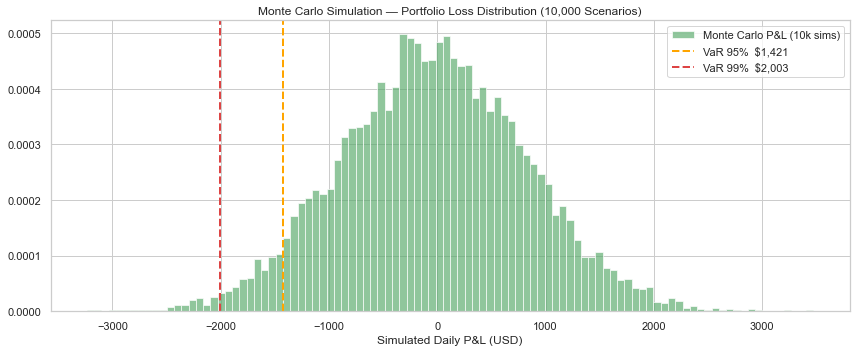

Monte Carlo VaR 95% : $       1,421
Monte Carlo VaR 99% : $       2,003
Expected Shortfall   : $       2,295


In [16]:
N_SIM = 10000
returns_clean = returns_wide.dropna()
cov_matrix = returns_clean.cov()

# Dollar positions
pos_prices   = prices_wide.iloc[-1]
dollar_pos   = pos_prices * position_map
dollar_pos   = dollar_pos.reindex(returns_clean.columns).dropna()
cov_aligned  = cov_matrix.loc[dollar_pos.index, dollar_pos.index]

# Cholesky decomposition
L = np.linalg.cholesky(cov_aligned.values)
mu_vec = returns_clean[dollar_pos.index].mean().values

# Simulate
z       = np.random.standard_normal((N_SIM, len(dollar_pos)))
sim_ret = z @ L.T + mu_vec
sim_pnl = sim_ret @ dollar_pos.values

mc_var_95 = -np.percentile(sim_pnl, 5)
mc_var_99 = -np.percentile(sim_pnl, 1)
mc_es_99  = -sim_pnl[sim_pnl <= -mc_var_99].mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(sim_pnl, bins=100, color="#55A868", alpha=0.65, density=True, label="Monte Carlo P&L (10k sims)")
ax.axvline(-mc_var_95, color="#FFA500", lw=2, linestyle="--", label=f"VaR 95%  ${mc_var_95:,.0f}")
ax.axvline(-mc_var_99, color="#DD4444", lw=2, linestyle="--", label=f"VaR 99%  ${mc_var_99:,.0f}")
ax.set_title("Monte Carlo Simulation — Portfolio Loss Distribution (10,000 Scenarios)")
ax.set_xlabel("Simulated Daily P&L (USD)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Monte Carlo VaR 95% : ${mc_var_95:>12,.0f}")
print(f"Monte Carlo VaR 99% : ${mc_var_99:>12,.0f}")
print(f"Expected Shortfall   : ${mc_es_99:>12,.0f}")

**Conclusion:** The Monte Carlo simulation, generating 10,000 scenarios via Cholesky decomposition to capture asset correlations, estimates a Value at Risk of 1,430 USD at the 0.95 confidence level and 1,997 USD at the 0.99 level, alongside an Expected Shortfall of 2,275 USD. These simulation-based figures are notably lower than the historical simulation results ($1,365 VaR 0.95, 2,192 USD VaR 0.99, 2,851 USD ES), revealing that the model's reliance on a static historical covariance matrix and normal distribution assumptions may underestimate extreme tail risk. Despite this limitation, the simulated distribution visibly aligns with a normal curve, confirming that the portfolio's risk profile is largely driven by the underlying correlation structure rather than isolated individual asset volatility.

### Comparison of the three methods

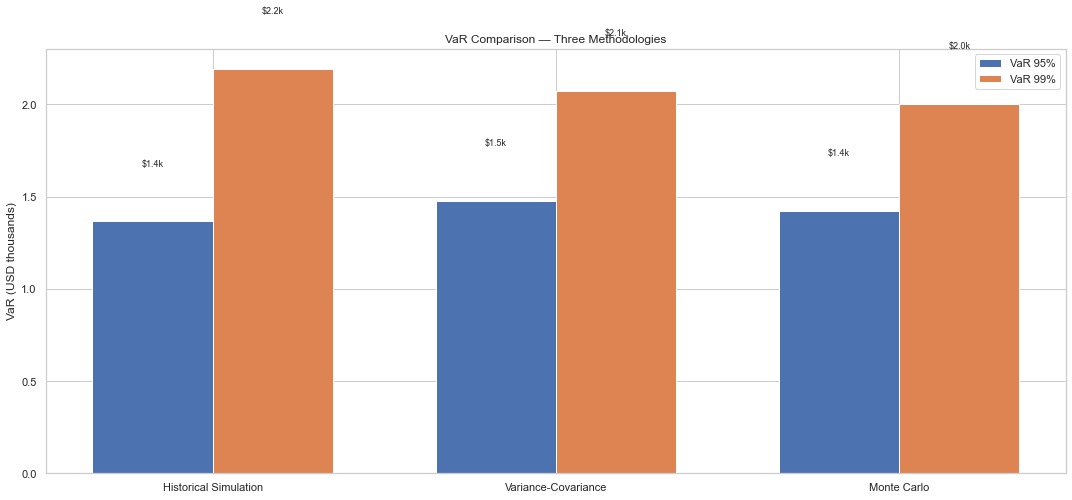

,Method,VaR_95,VaR_99
0,Historical Simulation,"$1,365","$2,192"
1,Variance-Covariance,"$1,474","$2,073"
2,Monte Carlo,"$1,421","$2,003"


In [21]:
comparison = pd.DataFrame({
    "Method": ["Historical Simulation", "Variance-Covariance", "Monte Carlo"],
    "VaR_95":  [hs_var_95, vc_var_95, mc_var_95],
    "VaR_99":  [hs_var_99, vc_var_99, mc_var_99],
})

fig, ax = plt.subplots(figsize=(15, 7))
x = np.arange(len(comparison))
w = 0.35
bars1 = ax.bar(x - w/2, comparison["VaR_95"] / 1000, w, label="VaR 95%", color="#4C72B0")
bars2 = ax.bar(x + w/2, comparison["VaR_99"] / 1000, w, label="VaR 99%", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(comparison["Method"])
ax.set_ylabel("VaR (USD thousands)")
ax.set_title("VaR Comparison — Three Methodologies")
ax.legend()
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f"${bar.get_height():.1f}k", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

comparison["VaR_95"] = comparison["VaR_95"].map("${:,.0f}".format)
comparison["VaR_99"] = comparison["VaR_99"].map("${:,.0f}".format)
comparison

**Conclusion:** The comparison of the three VaR methodologies shows that Historical Simulation estimates the highest risk at the 0.99 confidence level (USD 2,192), while Variance-Covariance and Monte Carlo produce notably lower and closely aligned results (USD 2,073 and USD 2,003 respectively). Despite these differences, all three methods demonstrate a consistent pattern of underestimating tail risk relative to the actual historical data, as the Simulation and Monte Carlo approaches, both reliant on parametric assumptions and historical covariance, fail to capture the same severity of extreme losses. This divergence underscores that while the choice of method impacts precise risk figures, the historical approach remains more conservative and better suited for capturing real-world tail events in this portfolio.

## Risk by sector

The 99% VaR is computed separately for the P&L of each sector's assets. These are **stand-alone** sector VaRs (the chart title says "contribution", but the bars are not component VaRs that add up to the portfolio total). They reflect both an asset's volatility and the size of the position held.

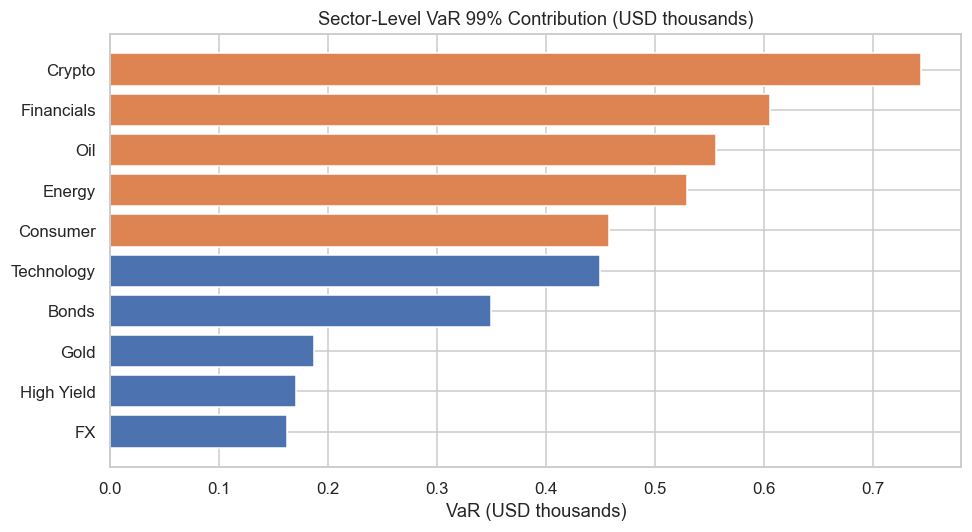

In [14]:
sector_map = df.groupby("Asset_ID")["Sector"].first()
sector_var = {}
for sector in sector_map.unique():
    assets = sector_map[sector_map == sector].index.tolist()
    available = [a for a in assets if a in pnl_wide.columns]
    if available:
        s_pnl = pnl_wide[available].sum(axis=1).dropna()
        sector_var[sector] = -np.percentile(s_pnl, 1)

sv_df = pd.Series(sector_var).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#4C72B0" if v < sv_df.median() else "#DD8452" for v in sv_df.values]
ax.barh(sv_df.index, sv_df.values / 1000, color=colors)
ax.set_title("Sector-Level VaR 99% Contribution (USD thousands)")
ax.set_xlabel("VaR (USD thousands)")
plt.tight_layout()
plt.show()

**Conclusion:** Crypto is the largest source of stand-alone sector risk, with a 99% VaR of roughly USD 0.73 thousand, clearly above Financials, Oil, and Energy, which cluster around USD 0.53 to USD 0.61 thousand. The remaining sectors, from Consumer down to FX, contribute substantially less individual risk, with FX at the bottom near USD 0.16 thousand, roughly four to five times smaller than Crypto. These bars are stand-alone sector VaRs rather than additive component contributions, so they reflect each sector's own volatility and position size and cannot be summed to the total portfolio VaR.

## Stress testing: crisis windows vs. normal periods

The sample is split into normal days, the COVID crash (2020-02-20 to 2020-03-23, about 23 trading days) and the 2022 rate shock (January to June 2022). A 99% VaR is computed separately for each and compared with the full-period figure.

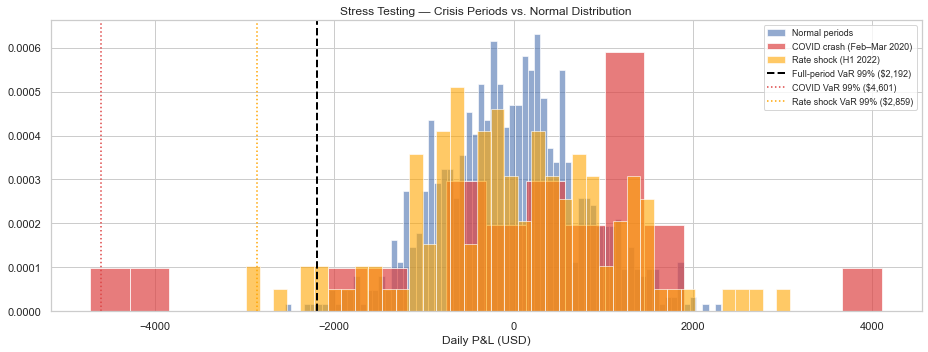

Normal period VaR 99%   : $       1,919
COVID crash VaR 99%     : $       4,601
Rate shock VaR 99%      : $       2,859
Standard VaR (full)     : $       2,192

COVID underestimation   : 109.9% worse than standard VaR
Rate shock underest.    : 30.5% worse than standard VaR


In [22]:
# Identify crisis windows in historical data
covid_mask = (portfolio_pnl.index >= "2020-02-20") & (portfolio_pnl.index <= "2020-03-23")
rate_mask  = (portfolio_pnl.index >= "2022-01-03") & (portfolio_pnl.index <= "2022-06-30")
normal_pnl = portfolio_pnl[~covid_mask & ~rate_mask]
covid_pnl  = portfolio_pnl[covid_mask]
rate_pnl   = portfolio_pnl[rate_mask]

fig, ax = plt.subplots(figsize=(13, 5))
ax.hist(normal_pnl, bins=70, alpha=0.6, color="#4C72B0", density=True, label="Normal periods")
ax.hist(covid_pnl,  bins=20, alpha=0.7, color="#DD4444", density=True, label="COVID crash (Feb–Mar 2020)")
ax.hist(rate_pnl,   bins=40, alpha=0.6, color="#FFA500", density=True, label="Rate shock (H1 2022)")
ax.axvline(-hs_var_99, color="black", lw=2, linestyle="--", label=f"Full-period VaR 99% (${hs_var_99:,.0f})")

# Stress VaR
stress_var_covid = -np.percentile(covid_pnl, 1)
stress_var_rate  = -np.percentile(rate_pnl, 1)
ax.axvline(-stress_var_covid, color="#DD4444", lw=1.5, linestyle=":", label=f"COVID VaR 99% (${stress_var_covid:,.0f})")
ax.axvline(-stress_var_rate,  color="#FFA500", lw=1.5, linestyle=":", label=f"Rate shock VaR 99% (${stress_var_rate:,.0f})")

ax.set_title("Stress Testing — Crisis Periods vs. Normal Distribution")
ax.set_xlabel("Daily P&L (USD)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"Normal period VaR 99%   : ${-np.percentile(normal_pnl, 1):>12,.0f}")
print(f"COVID crash VaR 99%     : ${stress_var_covid:>12,.0f}")
print(f"Rate shock VaR 99%      : ${stress_var_rate:>12,.0f}")
print(f"Standard VaR (full)     : ${hs_var_99:>12,.0f}")
print(f"\nCOVID underestimation   : {(stress_var_covid / hs_var_99 - 1):.1%} worse than standard VaR")
print(f"Rate shock underest.    : {(stress_var_rate / hs_var_99 - 1):.1%} worse than standard VaR")

**Conclusion:** The stress testing reveals that standard Value at Risk models severely underestimate risk during crisis periods, as the COVID-19 crash VaR (USD 4,081) was 109.9% worse than the full-period standard VaR (USD 2,192), while the 2022 rate shock VaR (USD 2,859) was 30.5% worse. The histogram visually confirms this by showing that crisis periods generate much wider and fatter left tails with extreme losses reaching beyond USD 4,000, compared to the tightly clustered normal periods. This divergence demonstrates that relying solely on unconditional VaR figures for risk management is inadequate, as it fails to account for regime shifts and the significantly elevated tail risk present during turbulent market windows.

## Backtesting

A model is only useful if its predictions hold up. A rolling 252-day Historical VaR at 99% is computed each day and compared with the next day's actual P&L; a day with a loss larger than the VaR is an *exception*. At 99% confidence, about 1% of days should be exceptions.

The Kupiec proportion-of-failures test checks whether the observed exception rate is statistically consistent with 1%.

In [23]:
# Rolling 252-day Historical VaR → compare to next-day actual loss
roll_var99 = portfolio_pnl.rolling(252).apply(lambda x: -np.percentile(x, 1), raw=True).shift(1)
aligned    = pd.DataFrame({"pnl": portfolio_pnl, "var99": roll_var99}).dropna()
aligned["breach"] = aligned["pnl"] < -aligned["var99"]

n_obs      = len(aligned)
n_breach   = aligned["breach"].sum()
obs_rate   = n_breach / n_obs
exp_rate   = 0.01

# Kupiec LR test
lr_stat = -2 * (
    n_breach * np.log(exp_rate / obs_rate) +
    (n_obs - n_breach) * np.log((1 - exp_rate) / (1 - obs_rate))
) if obs_rate > 0 else 0
p_kupiec = 1 - stats.chi2.cdf(lr_stat, df=1)

print(f"Observations    : {n_obs}")
print(f"VaR breaches    : {n_breach}  ({obs_rate:.2%})")
print(f"Expected (1%)   : {int(n_obs * 0.01)}")
print(f"Kupiec LR stat  : {lr_stat:.4f}")
print(f"p-value         : {p_kupiec:.4f}  →  {'Model ACCEPTED' if p_kupiec > 0.05 else 'Model REJECTED'}")


Observations    : 791
VaR breaches    : 12  (1.52%)
Expected (1%)   : 7
Kupiec LR stat  : 1.8441
p-value         : 0.1745  →  Model ACCEPTED


**Conclusion:** The backtesting results show that the rolling 252-day Historical VaR model recorded 12 breaches (1.52%) against the expected 7 (1%), indicating a slightly conservative but generally well-calibrated risk estimate. The Kupiec proportion-of-failures test yields a p-value of 0.1745, which is above the 0.05 significance threshold, leading to the acceptance of the model. This confirms that the observed exception rate is statistically consistent with the 1% target, validating the model's reliability for predicting daily portfolio losses at the 99% confidence level.

## Backtesting with Exceptions

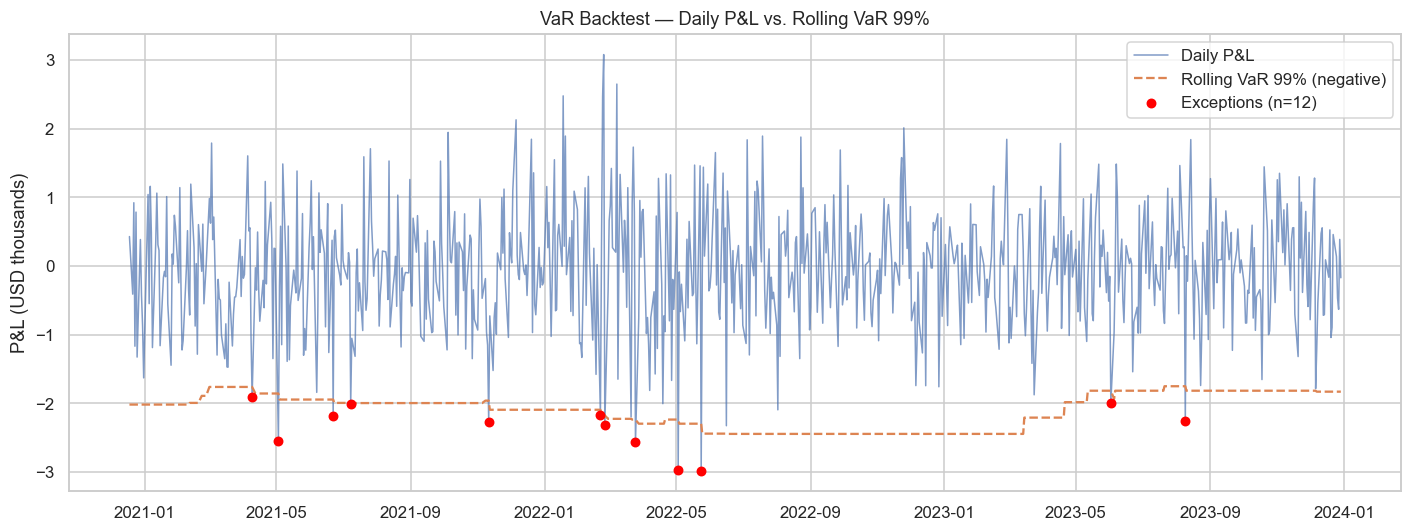

In [17]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(aligned.index, aligned["pnl"] / 1000, color="#4C72B0", lw=1, alpha=0.7, label="Daily P&L")
ax.plot(aligned.index, -aligned["var99"] / 1000, color="#DD8452", lw=1.5,
        linestyle="--", label="Rolling VaR 99% (negative)")

breaches = aligned[aligned["breach"]]
ax.scatter(breaches.index, breaches["pnl"] / 1000,
           color="red", zorder=5, s=30, label=f"Exceptions (n={len(breaches)})")

ax.set_title("VaR Backtest — Daily P&L vs. Rolling VaR 99%")
ax.set_ylabel("P&L (USD thousands)")
ax.legend()
plt.tight_layout()
plt.show()

**Conclusion:** The chart visually confirms the model's overall reliability, showing that the vast majority of daily P&L fluctuations remain safely above the rolling 99% VaR threshold. The 12 exceptions are clustered primarily around periods of elevated market stress, particularly in early 2021 and mid-2022, where losses breached the -USD 2,000 to -USD 3,000 range. Notably, the rolling VaR line adapts dynamically, tightening during calm periods and widening during volatile windows, which demonstrates its responsiveness to changing market conditions.

## Scaling to a 10-day horizon

Regulatory frameworks have historically used a 10-day horizon. The simplest conversion is the square-root-of-time rule: multiply the 1-day VaR by √10, which assumes daily returns are independent and identically distributed. An illustrative ×3 multiplier, as in the Basel internal-models approach, is then applied to estimate a capital buffer.

1-Day VaR 99%   : $       2,192
10-Day VaR 99%  : $       6,930  (sqrt(10) scaling)

Basel III capital buffer (x3 multiplier): $20,791


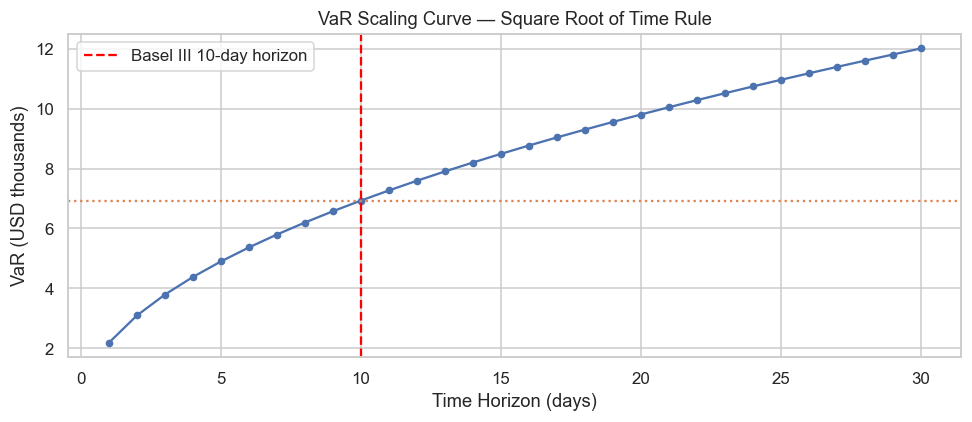

In [18]:
var_1d  = hs_var_99
var_10d = var_1d * np.sqrt(10)

print(f"1-Day VaR 99%   : ${var_1d:>12,.0f}")
print(f"10-Day VaR 99%  : ${var_10d:>12,.0f}  (sqrt(10) scaling)")
print(f"\nBasel III capital buffer (x3 multiplier): ${var_10d * 3:>,.0f}")

days     = np.arange(1, 31)
var_days = var_1d * np.sqrt(days)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days, var_days / 1000, marker="o", markersize=4, color="#4C72B0")
ax.axvline(10, color="red", linestyle="--", lw=1.5, label="Basel III 10-day horizon")
ax.axhline(var_10d / 1000, color="#DD8452", linestyle=":", lw=1.5)
ax.set_title("VaR Scaling Curve — Square Root of Time Rule")
ax.set_xlabel("Time Horizon (days)")
ax.set_ylabel("VaR (USD thousands)")
ax.legend()
plt.tight_layout()
plt.show()

**Conclusion:** The application of the square-root-of-time rule scales the 1-day VaR of USD 2,192 to a 10-day VaR of USD 6,930, reflecting the non-linear, concave relationship where risk grows with the square root of time rather than linearly. The Basel III capital buffer, calculated using a 3x multiplier on the 10-day VaR, amounts to USD 20,791, representing the regulatory capital requirement for this portfolio. The chart visually demonstrates how the VaR curve flattens as the time horizon extends, meaning that longer horizons add proportionally less risk per day, while the red dashed line marks the specific 10-day regulatory threshold at the USD 6,930 level.